# Predicting Secondary School Maths Performance

**Dataset.** UCI Student Performance (Maths class), 395 students from two Portuguese secondary schools, 33 variables covering demographics, family background, study habits and attendance.

**Why this dataset.** I taught mathematics and computing in schools for three years. The question I actually cared about in the staff room was not *who scored well* at the end of term, but *who was going to struggle, while there was still time to help them*. That framing shapes the whole analysis below.

**What this notebook does.**

1. Explores which factors move the final maths grade.
2. Builds a grade prediction model and shows why the obvious version of it is useless in practice.
3. Rebuilds it as an **early warning model** that only uses information available in the first week of term.
4. Turns it into a pass / fail classifier and evaluates it honestly, including the errors that matter most.

Grades run 0 to 20. A grade of 10 or above is a pass.

In [1]:
import warnings, json, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "semibold"

INK = "#1F2937"
ACCENT = "#2563EB"
ACCENT2 = "#DB2777"
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("data/student-mat.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 1. Data quality check

Before anything else: are there missing values, duplicates, or impossible entries?

In [2]:
print("Missing values per column:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nGrade ranges:")
print(df[["G1", "G2", "G3"]].describe().loc[["min", "max", "mean", "std"]].round(2))

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]
print(f"\n{len(num_cols)} numeric columns, {len(cat_cols)} categorical columns")

Missing values per column: 0
Duplicate rows: 0

Grade ranges:
         G1     G2     G3
min    3.00   0.00   0.00
max   19.00  19.00  20.00
mean  10.91  10.71  10.42
std    3.32   3.76   4.58

16 numeric columns, 17 categorical columns


The data is clean. No missing values, no duplicates, all grades inside the valid 0 to 20 range.

One thing stands out immediately and it matters later: the minimum for `G3` is 0, while `G1` and `G2` have higher minimums. A final grade of exactly zero usually means the student stopped turning up rather than that they sat the paper and scored nothing.

In [3]:
zeros = (df["G3"] == 0).sum()
print(f"Students with a final grade of exactly 0: {zeros} ({zeros/len(df):.1%})")
print(f"Of those, mean absences: {df.loc[df.G3 == 0, 'absences'].mean():.1f}")
print(f"Everyone else, mean absences: {df.loc[df.G3 > 0, 'absences'].mean():.1f}")
print(f"Of those, mean G2: {df.loc[df.G3 == 0, 'G2'].mean():.1f}")

Students with a final grade of exactly 0: 38 (9.6%)
Of those, mean absences: 0.0
Everyone else, mean absences: 6.3
Of those, mean G2: 4.7


Confirmed. The zero group has a second period grade near zero as well, so these are students who disengaged during the year rather than data errors. I keep them in. They are exactly the students an early warning system exists for.

## 2. What does the grade distribution look like?

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Pass rate: 67.1%   Fail rate: 32.9%
Mean final grade: 10.42   Median: 11.0


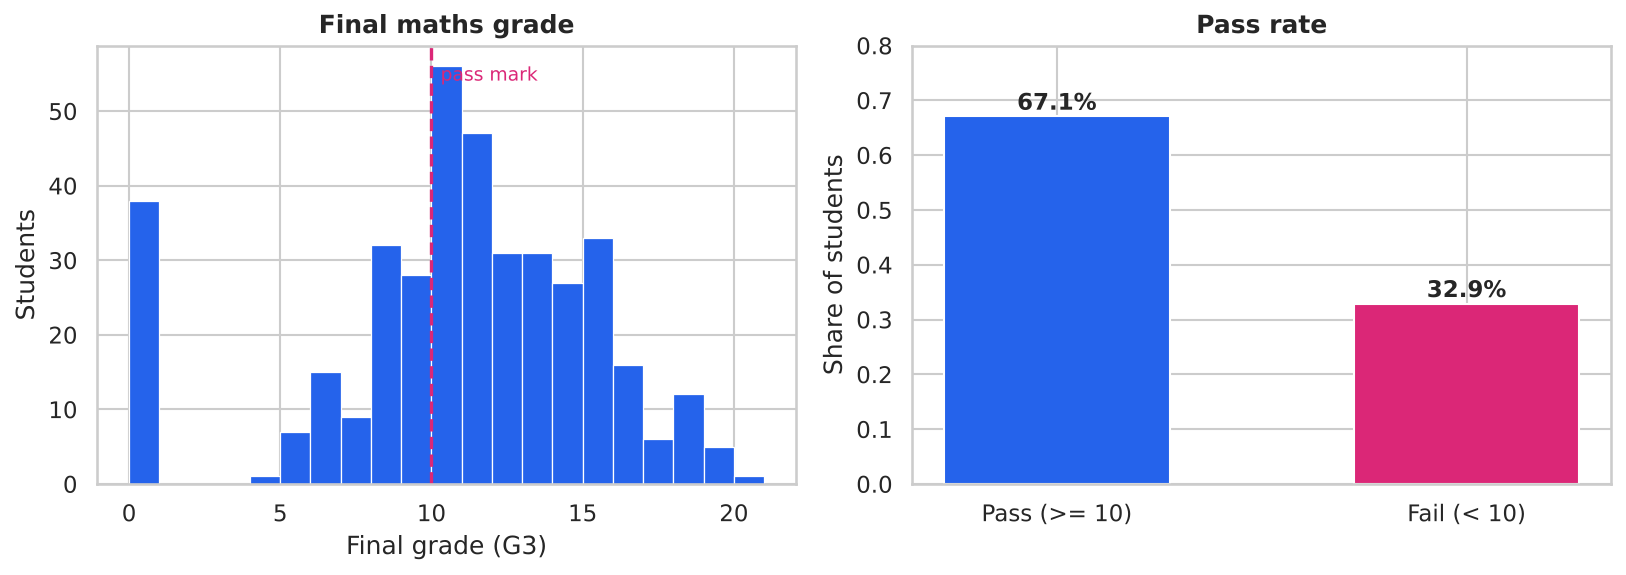

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["G3"], bins=21, range=(0, 21), color=ACCENT, edgecolor="white", linewidth=0.6)
axes[0].axvline(10, color=ACCENT2, linestyle="--", linewidth=1.6)
axes[0].text(10.3, axes[0].get_ylim()[1]*0.92, "pass mark", color=ACCENT2, fontsize=9)
axes[0].set_xlabel("Final grade (G3)")
axes[0].set_ylabel("Students")
axes[0].set_title("Final maths grade")

pass_rate = (df["G3"] >= 10).mean()
axes[1].bar(["Pass (>= 10)", "Fail (< 10)"], [pass_rate, 1 - pass_rate],
            color=[ACCENT, ACCENT2], width=0.55)
for i, v in enumerate([pass_rate, 1 - pass_rate]):
    axes[1].text(i, v + 0.012, f"{v:.1%}", ha="center", fontsize=11, fontweight="semibold")
axes[1].set_ylim(0, 0.8)
axes[1].set_ylabel("Share of students")
axes[1].set_title("Pass rate")

plt.tight_layout()
plt.savefig("figures/01_grade_distribution.png")
plt.show()

print(f"Pass rate: {pass_rate:.1%}   Fail rate: {1-pass_rate:.1%}")
print(f"Mean final grade: {df['G3'].mean():.2f}   Median: {df['G3'].median():.1f}")

Roughly a third of the class fails. The spike at zero is clearly visible on the left of the histogram and it pulls the mean down below the median.

## 3. Which factors actually relate to the final grade?

I start with the numeric variables and a correlation matrix, then look at the categorical ones separately.

Correlation with final grade, strongest first:

G2            0.905
G1            0.801
failures     -0.360
Medu          0.217
age          -0.162
Fedu          0.152
goout        -0.133
traveltime   -0.117
studytime     0.098
health       -0.061
Dalc         -0.055
Walc         -0.052
famrel        0.051
absences      0.034
freetime      0.011


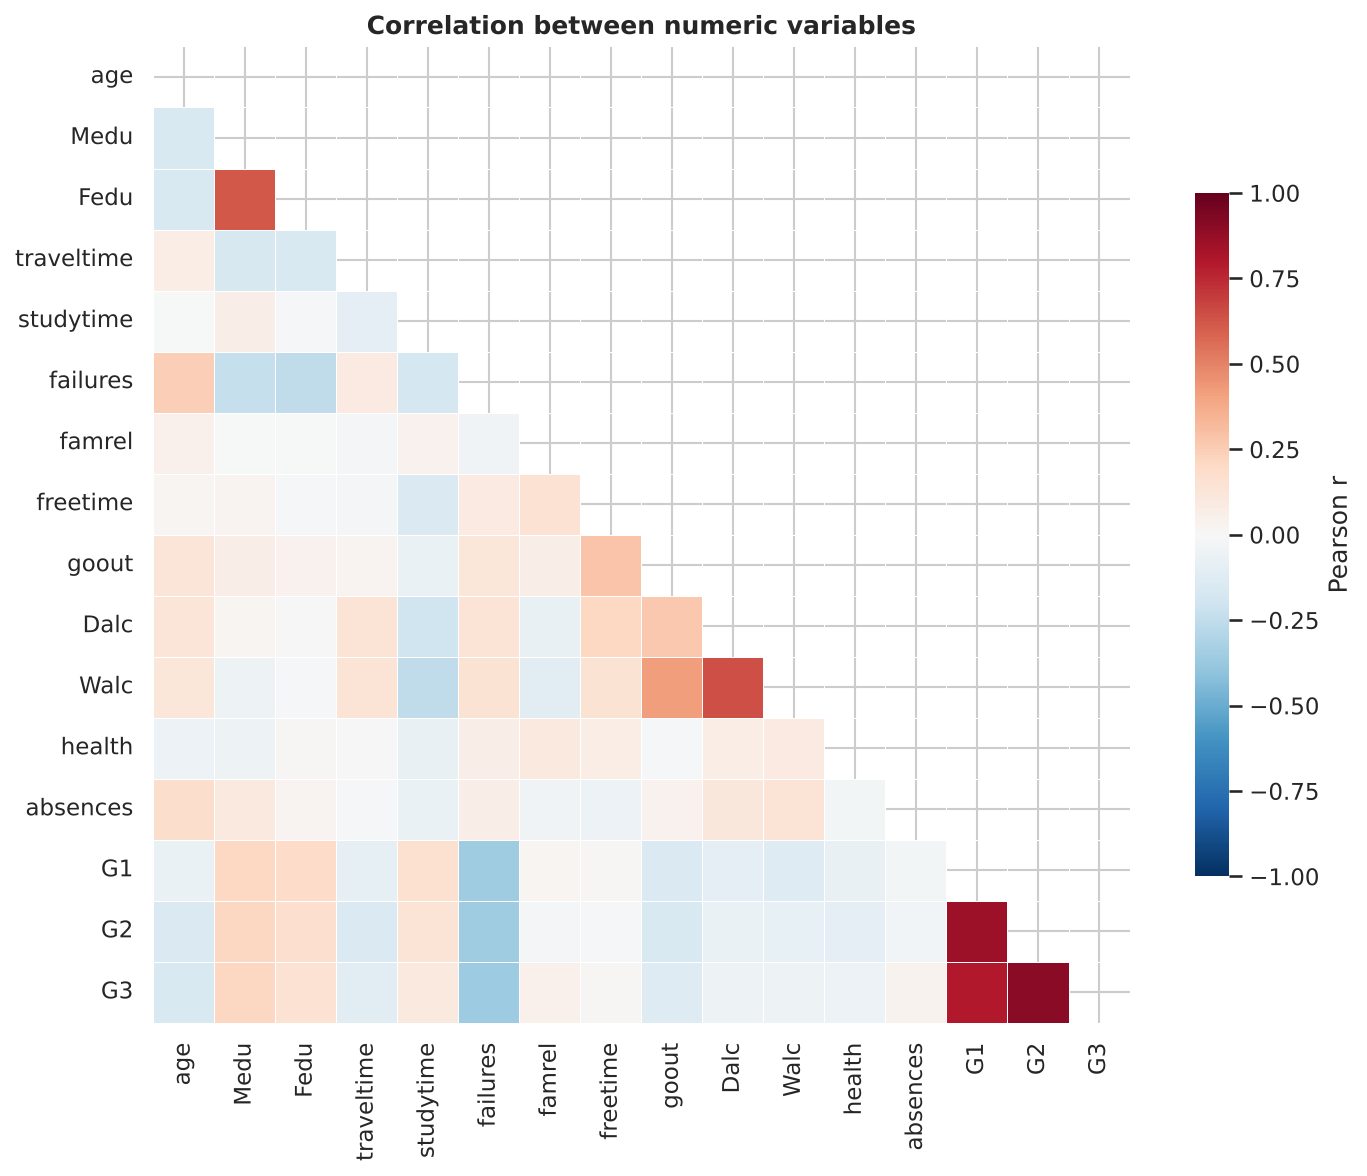

In [5]:
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.7, "label": "Pearson r"},
            ax=ax, annot=False)
ax.set_title("Correlation between numeric variables")
plt.tight_layout()
plt.savefig("figures/02_correlation_matrix.png")
plt.show()

g3_corr = corr["G3"].drop("G3").sort_values(key=abs, ascending=False)
print("Correlation with final grade, strongest first:\n")
print(g3_corr.round(3).to_string())

`G1` and `G2` dominate everything else, which is unsurprising: they are the same student's maths grade from the first and second marking periods.

Setting those aside, the strongest honest signal is **past failures**, followed by mother's education, study time and going out with friends.

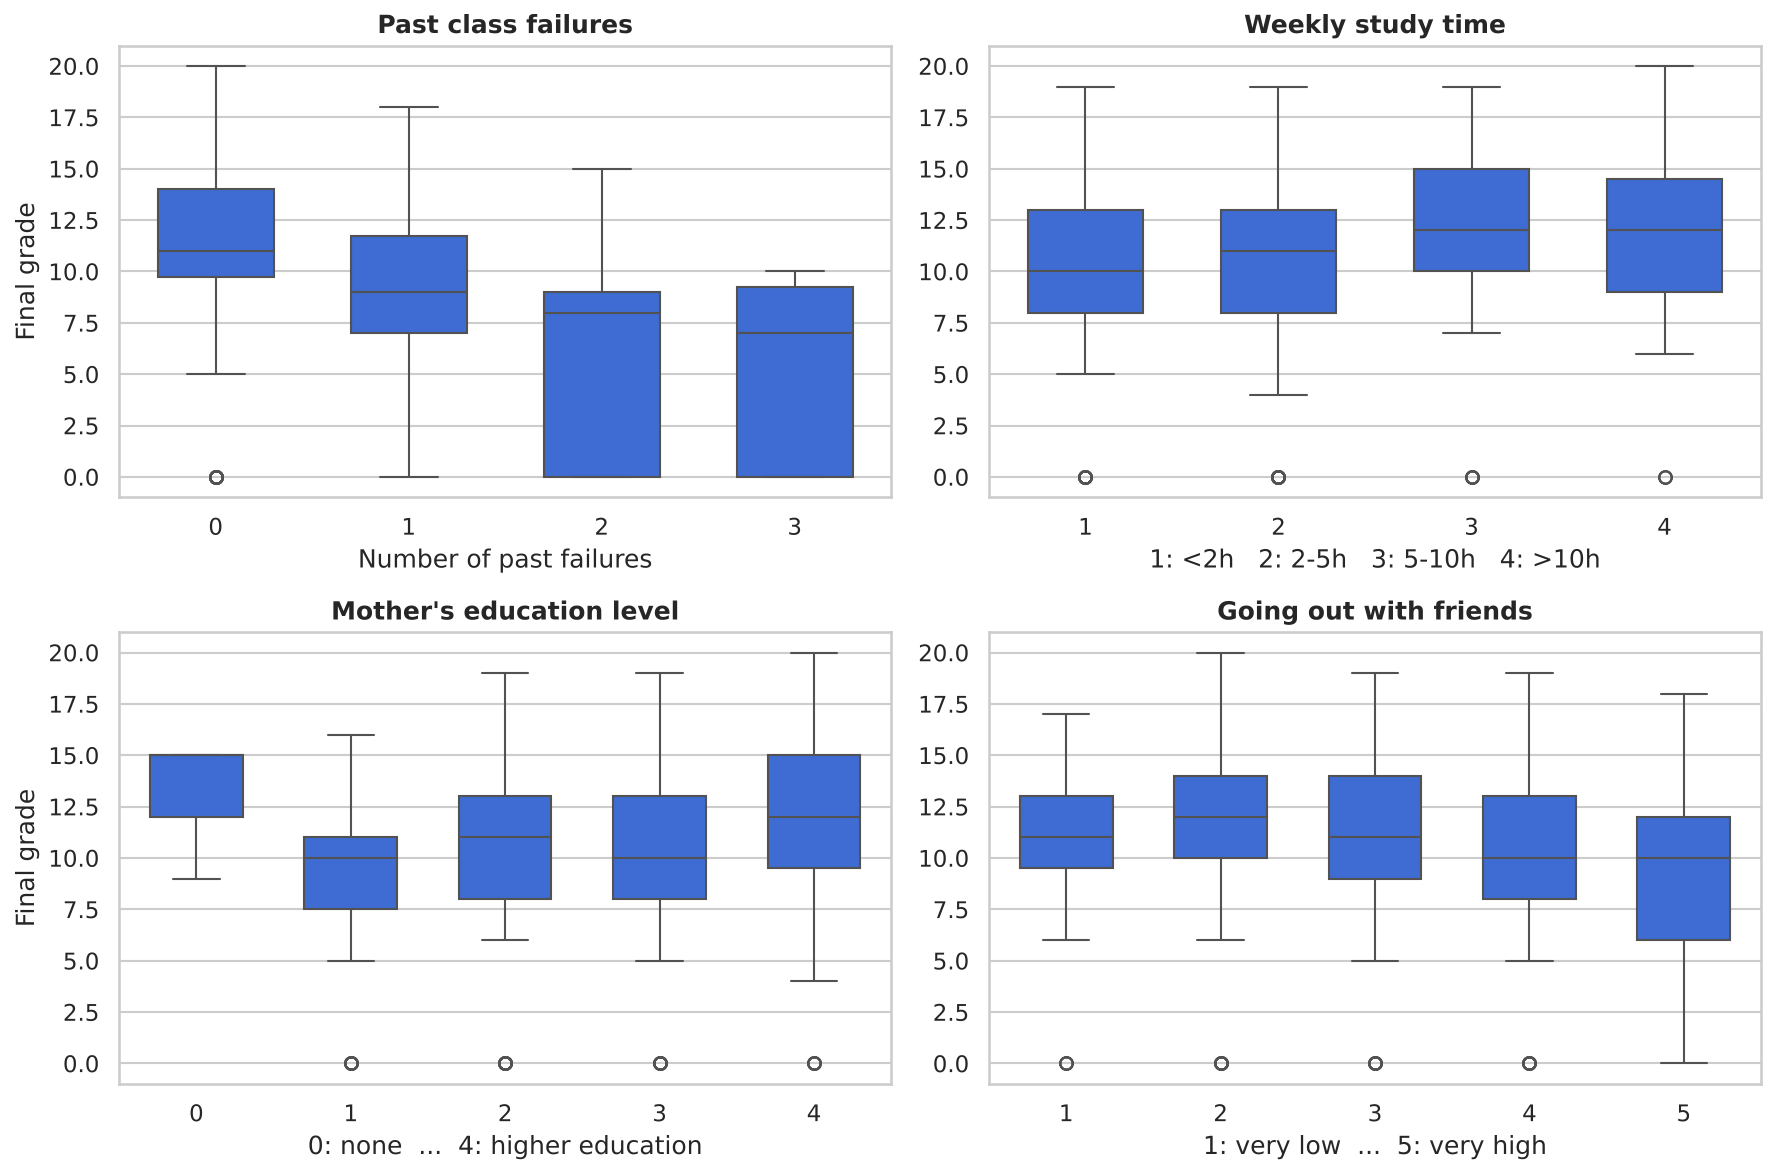

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(data=df, x="failures", y="G3", ax=axes[0, 0], color=ACCENT, width=0.6)
axes[0, 0].set_title("Past class failures")
axes[0, 0].set_xlabel("Number of past failures")
axes[0, 0].set_ylabel("Final grade")

sns.boxplot(data=df, x="studytime", y="G3", ax=axes[0, 1], color=ACCENT, width=0.6)
axes[0, 1].set_title("Weekly study time")
axes[0, 1].set_xlabel("1: <2h   2: 2-5h   3: 5-10h   4: >10h")
axes[0, 1].set_ylabel("")

sns.boxplot(data=df, x="Medu", y="G3", ax=axes[1, 0], color=ACCENT, width=0.6)
axes[1, 0].set_title("Mother's education level")
axes[1, 0].set_xlabel("0: none  ...  4: higher education")
axes[1, 0].set_ylabel("Final grade")

sns.boxplot(data=df, x="goout", y="G3", ax=axes[1, 1], color=ACCENT, width=0.6)
axes[1, 1].set_title("Going out with friends")
axes[1, 1].set_xlabel("1: very low  ...  5: very high")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/03_key_factors.png")
plt.show()

In [7]:
rows = []
for c in cat_cols:
    g = df.groupby(c)["G3"].agg(["mean", "count"])
    if len(g) == 2:
        (a, b) = g.index.tolist()
        rows.append({
            "variable": c,
            "groups": f"{a} vs {b}",
            "mean_gap": round(g.loc[a, "mean"] - g.loc[b, "mean"], 2),
            "n_smaller_group": int(g["count"].min()),
        })

gaps = pd.DataFrame(rows).sort_values("mean_gap", key=abs, ascending=False)
print("Binary categorical variables, gap in mean final grade:\n")
print(gaps.to_string(index=False))

Binary categorical variables, gap in mean final grade:

  variable     groups  mean_gap  n_smaller_group
    higher  no vs yes     -3.81               20
  romantic  no vs yes      1.26              132
  internet  no vs yes     -1.21               66
   address     R vs U     -1.16               88
 schoolsup  no vs yes      1.13               51
       sex     F vs M     -0.95              187
      paid  no vs yes     -0.94              181
   Pstatus     A vs T      0.87               41
   famsize GT3 vs LE3     -0.82              114
    school   GP vs MS      0.64               46
   nursery  no vs yes     -0.58               81
    famsup  no vs yes      0.37              153
activities  no vs yes     -0.15              194


Two of these are worth pausing on.

`higher` (whether the student wants to go on to higher education) shows the largest gap, but only 20 students said no, so the estimate is noisy. `schoolsup` (extra school support) goes the *wrong* way at first glance, with supported students scoring lower. That is not the support failing. It is selection: schools assign extra support to the students already struggling. Reading that coefficient as causal would be a real mistake, and it is the kind of thing a model will happily reproduce.

## 4. The modelling trap

The obvious model predicts `G3` from everything, including `G1` and `G2`. Let me build it and then explain why I would not ship it.

In [8]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y = df["G3"]

def make_pipeline(model, feature_frame):
    num = feature_frame.select_dtypes(include=np.number).columns.tolist()
    cat = [c for c in feature_frame.columns if c not in num]
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat),
    ])
    return Pipeline([("pre", pre), ("model", model)])

# Model A: everything, prior grades included
X_all = df.drop(columns=["G3"])
# Model B: early warning, nothing from the school year itself
X_early = df.drop(columns=["G3", "G1", "G2"])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

for label, X in [("A. With G1 and G2", X_all), ("B. Early warning", X_early)]:
    for name, model in [("Ridge", Ridge(alpha=1.0)),
                        ("Random forest", RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1))]:
        pipe = make_pipeline(model, X)
        r2 = cross_val_score(pipe, X, y, cv=cv, scoring="r2")
        mae = -cross_val_score(pipe, X, y, cv=cv, scoring="neg_mean_absolute_error")
        results[f"{label} | {name}"] = {"r2_mean": r2.mean(), "r2_std": r2.std(), "mae_mean": mae.mean()}

res = pd.DataFrame(results).T
res.columns = ["R2 (mean)", "R2 (std)", "MAE (grade points)"]
print("5-fold cross validation\n")
print(res.round(3).to_string())

5-fold cross validation

                                   R2 (mean)  R2 (std)  MAE (grade points)
A. With G1 and G2 | Ridge              0.793     0.042               1.370
A. With G1 and G2 | Random forest      0.871     0.053               1.026
B. Early warning | Ridge               0.033     0.146               3.407
B. Early warning | Random forest       0.303     0.029               2.853


Model A looks excellent. Model B looks mediocre. The temptation is to report Model A and move on.

Here is the problem. `G2` is the maths grade from the second marking period, recorded a few weeks before `G3`. A model that needs `G2` to predict `G3` cannot tell a teacher anything in September, which is the only moment the prediction would have changed what anyone did. By the time `G2` exists, the teacher already knows who is struggling and does not need a model to say so.

Model A is not wrong. It is just answering a question nobody asked.

**Model B is the one worth building.** It uses only information available before teaching starts: demographics, family background, travel time, past failures, stated study habits, support arrangements. Its job is harder and its numbers are lower, and that is the honest picture.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


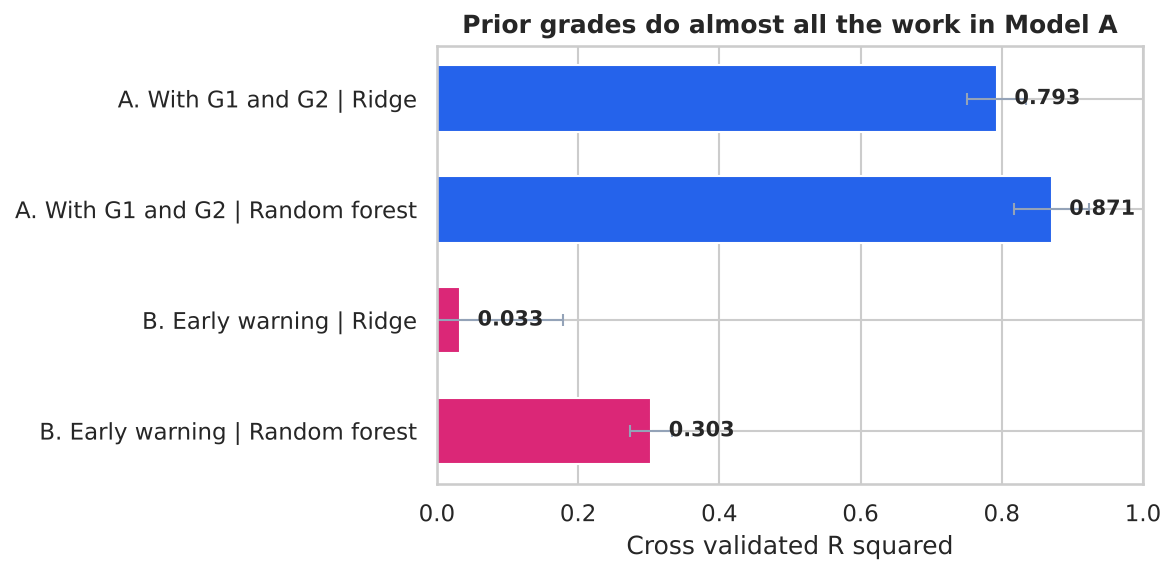

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = list(results.keys())
vals = [results[k]["r2_mean"] for k in labels]
errs = [results[k]["r2_std"] for k in labels]
colors = [ACCENT if k.startswith("A.") else ACCENT2 for k in labels]

bars = ax.barh(range(len(labels)), vals, xerr=errs, color=colors, height=0.6,
               error_kw={"ecolor": "#94A3B8", "capsize": 3, "lw": 1})
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.0)
ax.set_xlabel("Cross validated R squared")
ax.set_title("Prior grades do almost all the work in Model A")
for i, v in enumerate(vals):
    ax.text(v + 0.025, i, f"{v:.3f}", va="center", fontsize=10, fontweight="semibold")
plt.tight_layout()
plt.savefig("figures/04_model_comparison.png")
plt.show()

## 5. Reframing as an early warning classifier

Predicting a grade to one decimal place is not what a school needs. What a head of department needs in week one is a shortlist: *which students should we watch*.

So: binary target, pass or fail, using only pre-term information.

**A note on how I evaluate this.** With 395 students, a single held-out test set leaves about 99 students, and a quarter of those are failures. Estimates from a sample that small swing wildly depending on which students happen to land in the split. I ran it that way first and the held-out AUC came out more than 0.1 below the cross validated figure, which tells you about the split rather than about the model.

So I use repeated stratified cross validation for model selection, and out-of-fold predictions across all 395 students for the final evaluation. Every student is scored by a model that never saw them during training, and no result rests on one lucky or unlucky split.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score)

y_cls = (df["G3"] >= 10).astype(int)   # 1 = pass, 0 = fail
X_cls = df.drop(columns=["G3", "G1", "G2"])

print(f"{len(y_cls)} students, {y_cls.sum()} pass, {(1-y_cls).sum()} fail")

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=RANDOM_STATE)

candidates = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE),
}

cv_rows = []
for name, model in candidates.items():
    pipe = make_pipeline(model, X_cls)
    auc = cross_val_score(pipe, X_cls, y_cls, cv=rskf, scoring="roc_auc", n_jobs=-1)
    cv_rows.append({
        "model": name,
        "ROC AUC (mean)": auc.mean(),
        "ROC AUC (std)": auc.std(),
        "worst fold": auc.min(),
        "best fold": auc.max(),
    })

cv_table = pd.DataFrame(cv_rows).sort_values("ROC AUC (mean)", ascending=False)
print("\n30 fits each: 5-fold cross validation repeated 6 times\n")
print(cv_table.round(3).to_string(index=False))

395 students, 265 pass, 130 fail



30 fits each: 5-fold cross validation repeated 6 times

              model  ROC AUC (mean)  ROC AUC (std)  worst fold  best fold
      Random forest           0.691          0.049       0.586      0.781
Logistic regression           0.684          0.050       0.570      0.787
  Gradient boosting           0.658          0.058       0.542      0.774


The spread between the worst and best fold is wide for every model. That is the honest reality of a 395 row dataset, and it is exactly why I am not quoting a single split.

In [11]:
best_name = cv_table.iloc[0]["model"]
best = make_pipeline(candidates[best_name], X_cls)

# Out-of-fold probabilities: every student scored by a model that never trained on them.
# Averaged over several repeats so the result does not depend on one fold assignment.
oof_runs = []
for seed in range(8):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
    oof_runs.append(cross_val_predict(best, X_cls, y_cls, cv=skf,
                                      method="predict_proba", n_jobs=-1)[:, 1])
proba = np.mean(oof_runs, axis=0)

oof_auc = roc_auc_score(y_cls, proba)
print(f"Chosen model: {best_name}")
print(f"Out-of-fold ROC AUC across all {len(y_cls)} students: {oof_auc:.3f}\n")
print(classification_report(y_cls, (proba >= 0.5).astype(int),
                            target_names=["Fail", "Pass"], digits=3))

Chosen model: Random forest
Out-of-fold ROC AUC across all 395 students: 0.687

              precision    recall  f1-score   support

        Fail      0.512     0.485     0.498       130
        Pass      0.754     0.774     0.764       265

    accuracy                          0.678       395
   macro avg      0.633     0.629     0.631       395
weighted avg      0.674     0.678     0.676       395



### The question is not "what threshold", it is "how many students can we actually help"

A probability cut-off is the wrong unit to think in. A school does not decide "we will support everyone below 0.62". It decides "we have one teacher and four free periods a week, so we can take on twenty students". The real constraint is capacity.

So I rank every student by predicted risk and ask: if we work down that ranking as far as our capacity allows, how many of the students who actually go on to fail do we reach, compared with picking names at random?

In [12]:
y_fail = (1 - y_cls).values
p_fail = 1 - proba
baseline = y_fail.mean()

order = np.argsort(-p_fail)                 # highest predicted risk first
gains = np.cumsum(y_fail[order]) / y_fail.sum()
share = np.arange(1, len(order) + 1) / len(order)

rows = []
for cap in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    k = int(round(cap * len(order)))
    caught = y_fail[order][:k].sum()
    rows.append({
        "capacity": f"top {cap:.0%}",
        "students seen": k,
        "failures caught": int(caught),
        "of all failures": caught / y_fail.sum(),
        "hit rate": caught / k,
        "lift vs random": (caught / k) / baseline,
    })

capacity = pd.DataFrame(rows)
print(f"Base rate: {baseline:.1%} of students fail\n")
print(capacity.assign(**{
    "of all failures": lambda d: (d["of all failures"]*100).round(1).astype(str) + "%",
    "hit rate": lambda d: (d["hit rate"]*100).round(1).astype(str) + "%",
    "lift vs random": lambda d: d["lift vs random"].round(2).astype(str) + "x",
}).to_string(index=False))

# Pick a realistic operating point: support the top quarter of the risk ranking.
cap = 0.25
k = int(round(cap * len(order)))
cut = np.sort(p_fail)[::-1][k - 1]
pred_tuned = (p_fail < cut).astype(int)     # 1 = predicted pass, 0 = flagged
cm = confusion_matrix(y_cls, pred_tuned, labels=[0, 1])
flagged = (pred_tuned == 0).mean()
recall_at_cap = y_fail[order][:k].sum() / y_fail.sum()
precision_at_cap = y_fail[order][:k].sum() / k

Base rate: 32.9% of students fail

capacity  students seen  failures caught of all failures hit rate lift vs random
 top 10%             40               26           20.0%    65.0%          1.98x
 top 15%             59               38           29.2%    64.4%          1.96x
 top 20%             79               46           35.4%    58.2%          1.77x
 top 25%             99               55           42.3%    55.6%          1.69x
 top 30%            118               62           47.7%    52.5%           1.6x
 top 40%            158               73           56.2%    46.2%           1.4x
 top 50%            198               84           64.6%    42.4%          1.29x


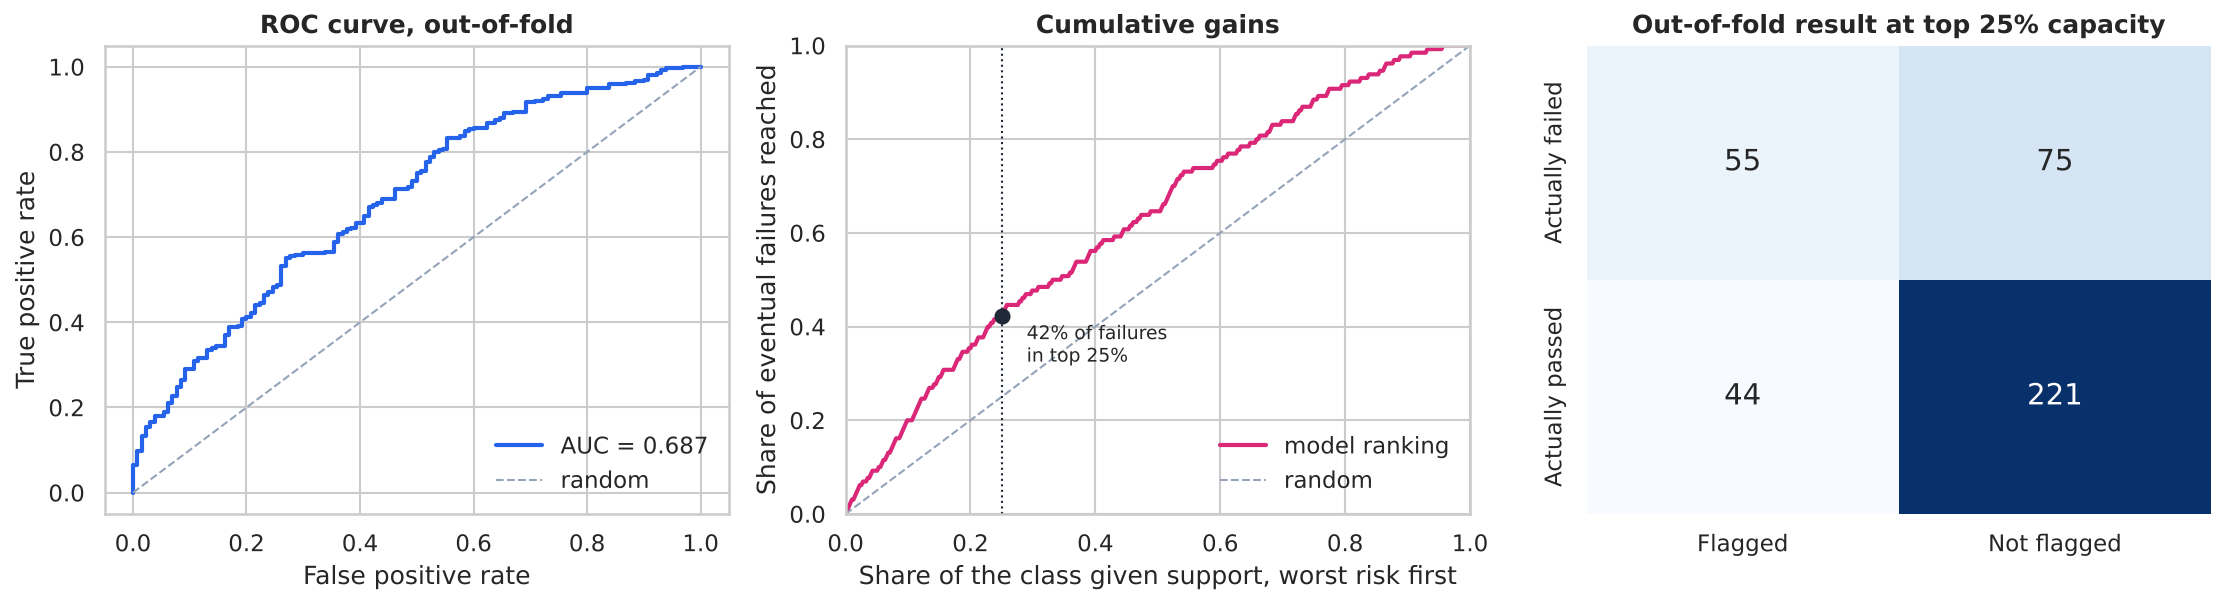

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

fpr, tpr, _ = roc_curve(y_cls, proba)
axes[0].plot(fpr, tpr, color=ACCENT, lw=2, label=f"AUC = {oof_auc:.3f}")
axes[0].plot([0, 1], [0, 1], color="#94A3B8", ls="--", lw=1, label="random")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve, out-of-fold")
axes[0].legend(loc="lower right", frameon=False)

axes[1].plot(share, gains, color=ACCENT2, lw=2, label="model ranking")
axes[1].plot([0, 1], [0, 1], color="#94A3B8", ls="--", lw=1, label="random")
axes[1].axvline(cap, color=INK, lw=1, ls=":")
axes[1].scatter([cap], [recall_at_cap], color=INK, zorder=5, s=45)
axes[1].annotate(f"{recall_at_cap:.0%} of failures\nin top {cap:.0%}",
                 (cap, recall_at_cap), textcoords="offset points",
                 xytext=(12, -22), fontsize=9)
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Share of the class given support, worst risk first")
axes[1].set_ylabel("Share of eventual failures reached")
axes[1].set_title("Cumulative gains")
axes[1].legend(loc="lower right", frameon=False)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Flagged", "Not flagged"],
            yticklabels=["Actually failed", "Actually passed"], annot_kws={"size": 14})
axes[2].set_title(f"Out-of-fold result at top {cap:.0%} capacity")

plt.tight_layout()
plt.savefig("figures/05_classifier_evaluation.png")
plt.show()

## 6. What is the model keying on?

Permutation importance, computed inside each fold on that fold's held-out students and then averaged. Measuring it on data the model trained on would mostly tell me how well it memorised.

  feature  importance     sd
 failures      0.0912 0.0131
 absences      0.0237 0.0112
schoolsup      0.0204 0.0148
    goout      0.0170 0.0208
      sex      0.0109 0.0040
      age      0.0075 0.0056
   famsup      0.0063 0.0082
   higher      0.0043 0.0020
  address      0.0040 0.0041
   reason      0.0037 0.0067
 romantic      0.0023 0.0107
     Walc      0.0022 0.0039


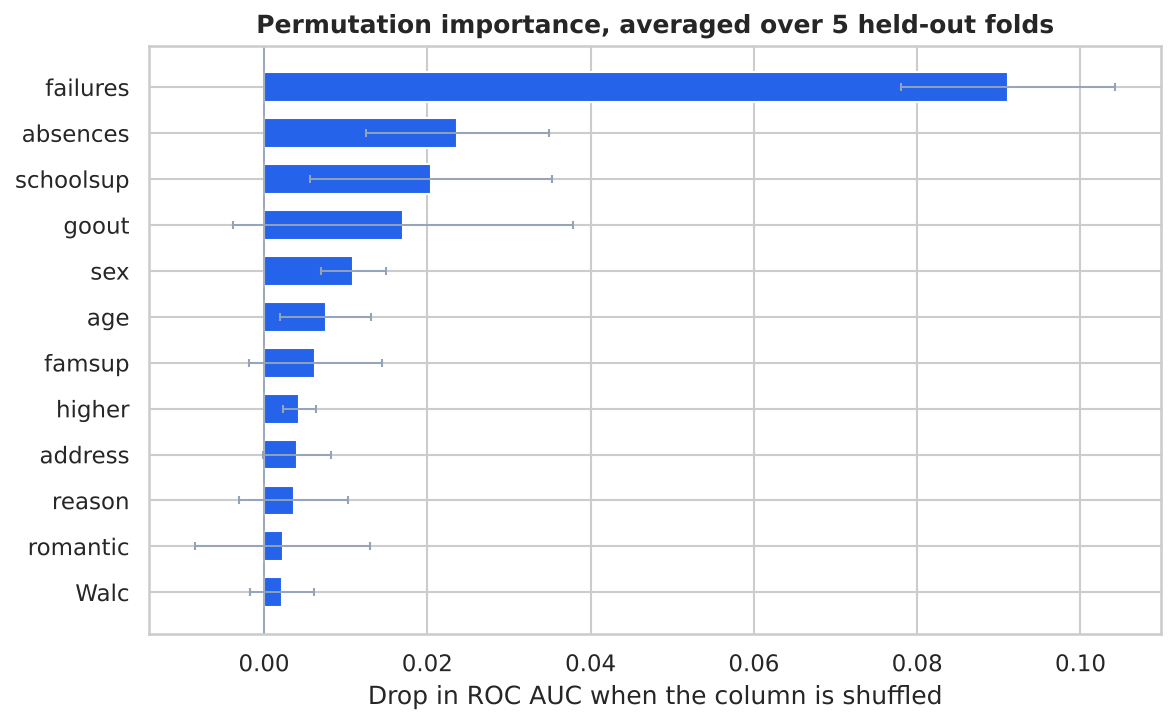

In [14]:
from sklearn.inspection import permutation_importance

fold_scores = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for tr_idx, te_idx in skf.split(X_cls, y_cls):
    m = make_pipeline(candidates[best_name], X_cls)
    m.fit(X_cls.iloc[tr_idx], y_cls.iloc[tr_idx])
    r = permutation_importance(m, X_cls.iloc[te_idx], y_cls.iloc[te_idx],
                               n_repeats=20, random_state=RANDOM_STATE,
                               scoring="roc_auc", n_jobs=-1)
    fold_scores.append(r.importances_mean)

arr = np.vstack(fold_scores)
imp = (pd.DataFrame({"feature": X_cls.columns,
                     "importance": arr.mean(axis=0),
                     "sd": arr.std(axis=0)})
       .sort_values("importance", ascending=False)
       .head(12))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp["feature"][::-1], imp["importance"][::-1], xerr=imp["sd"][::-1],
        color=ACCENT, height=0.65, error_kw={"ecolor": "#94A3B8", "capsize": 2, "lw": 0.9})
ax.axvline(0, color="#94A3B8", lw=0.8)
ax.set_xlabel("Drop in ROC AUC when the column is shuffled")
ax.set_title("Permutation importance, averaged over 5 held-out folds")
plt.tight_layout()
plt.savefig("figures/06_feature_importance.png")
plt.show()

print(imp.round(4).to_string(index=False))

## 7. Findings

**Past failures are the single strongest pre-term signal.** A student who has already repeated a class is the one to watch from day one, ahead of any family or lifestyle variable.

**Home background matters, but less than people assume.** Mother's education shows up consistently, father's much less. Neither comes close to prior academic history.

**The early warning model is usefully better than guessing, and nowhere near certain.** Ranked by predicted risk, the top quarter of the class contains a clearly higher share of eventual failures than a random quarter would. That is a workable shortlist for a head of department working under a real capacity limit. It is not a verdict on any individual student and should never be presented as one. The gains curve above is the honest summary: the model sorts better than chance, and it is a long way from sorting perfectly.

**The high-accuracy version of this model is the useless one.** Including second-period grades pushes R squared past 0.8 and makes the model worthless, because it only works at a point in the year when the teacher already has the answer.

## 8. Limitations

395 students from two schools in one country in one year. Portuguese grading on a 0 to 20 scale does not transfer directly to other systems. Several variables are self-reported, including study time and alcohol use, and self-reports about effort are optimistic in predictable directions. The `schoolsup` variable is confounded by how schools assign support, so none of these relationships should be read as causal. Finally, deploying anything like this in a real school raises fairness questions that are not solved by a better AUC: a model that flags students by family background can quietly become a label they carry.

**Data source.** P. Cortez and A. Silva, "Using Data Mining to Predict Secondary School Student Performance", UCI Machine Learning Repository.

In [15]:
metrics = {
    "dataset": "UCI Student Performance (maths)",
    "n_students": int(len(df)),
    "n_features": int(df.shape[1] - 1),
    "pass_rate": round(float(pass_rate), 4),
    "regression_cv": {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in results.items()},
    "classifier": best_name,
    "cv_roc_auc_mean": round(float(cv_table.iloc[0]["ROC AUC (mean)"]), 4),
    "cv_roc_auc_std": round(float(cv_table.iloc[0]["ROC AUC (std)"]), 4),
    "oof_roc_auc": round(float(oof_auc), 4),
    "capacity_setting": f"top {cap:.0%} of risk ranking",
    "students_supported": int(k),
    "recall_on_failing": round(float(recall_at_cap), 4),
    "precision_on_failing": round(float(precision_at_cap), 4),
    "base_rate_failing": round(float(baseline), 4),
    "lift_over_random": round(float(precision_at_cap / baseline), 3),
    "capacity_table": capacity.round(4).to_dict(orient="records"),
    "top_features": imp["feature"].head(6).tolist(),
}
with open("metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))

{
  "dataset": "UCI Student Performance (maths)",
  "n_students": 395,
  "n_features": 32,
  "pass_rate": 0.6709,
  "regression_cv": {
    "A. With G1 and G2 | Ridge": {
      "r2_mean": 0.793,
      "r2_std": 0.0418,
      "mae_mean": 1.3702
    },
    "A. With G1 and G2 | Random forest": {
      "r2_mean": 0.8705,
      "r2_std": 0.0531,
      "mae_mean": 1.0258
    },
    "B. Early warning | Ridge": {
      "r2_mean": 0.0326,
      "r2_std": 0.146,
      "mae_mean": 3.4066
    },
    "B. Early warning | Random forest": {
      "r2_mean": 0.3034,
      "r2_std": 0.0295,
      "mae_mean": 2.8532
    }
  },
  "classifier": "Random forest",
  "cv_roc_auc_mean": 0.6906,
  "cv_roc_auc_std": 0.0495,
  "oof_roc_auc": 0.6873,
  "capacity_setting": "top 25% of risk ranking",
  "students_supported": 99,
  "recall_on_failing": 0.4231,
  "precision_on_failing": 0.5556,
  "base_rate_failing": 0.3291,
  "lift_over_random": 1.688,
  "capacity_table": [
    {
      "capacity": "top 10%",
      "stud